# Motor Bearing Failure Prediction from Vibration Signals

**Problem.** Small mills (rice, flour, textile, saw mills) run induction motors with no condition monitoring.
When a bearing fails the motor stops without warning: the production loss is often bigger than the repair.
Bearings rarely fail suddenly, though. A small spall on a race starts sending a short impact every time a ball
rolls over it, months before the bearing seizes. Those impacts can be seen in the vibration signal.

**Goal.** From a short vibration recording:
1. **Early warning:** is this motor drifting away from its own healthy baseline? (no fault labels needed)
2. **Diagnosis:** if a fault is present, is it the inner race, outer race or a rolling element (ball)?

**Data.**
* Public: Case Western Reserve University (CWRU) bearing dataset: 12 kHz drive-end accelerometer, healthy
  bearings and seeded faults of 0.007", 0.014" and 0.021" on the inner race, ball and outer race, at motor
  loads 0-3 hp. 40 recordings.
* Own data: phone recordings of a fan (accelerometer via phyphox, or microphone). Section 9 runs on whatever
  is in `data/phone/` and skips cleanly when the folder is empty.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from bearing import catalog as C, signals as S, anomaly as A

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RAW = ROOT / "data" / "raw" / "cwru"
FS = C.FS_CWRU
COLORS = {"Normal": "#2a9d8f", "Inner race": "#e76f51", "Ball": "#e9c46a", "Outer race": "#264653"}

## 1. Get the data
Downloads the 40 CWRU `.mat` files (~134 MB) if they are not already in `data/raw/cwru/`.

In [2]:
if len(list(RAW.glob("*.mat"))) < len(C.FILES):
    import runpy; runpy.run_path(str(ROOT / "scripts" / "download_cwru.py"))
catalog = pd.DataFrame(C.FILES, columns=["file_id", "fault", "size_in", "load_hp"])
recs = {}
for r in catalog.itertuples():
    x, rpm = S.load_cwru_mat(RAW / f"{r.file_id}.mat")
    recs[r.file_id] = (x, rpm or [1797, 1772, 1750, 1730][r.load_hp])
catalog["rpm"] = [recs[i][1] for i in catalog.file_id]
catalog["seconds"] = [len(recs[i][0]) / FS for i in catalog.file_id]
catalog.groupby(["fault", "size_in"]).agg(files=("file_id", "count"), seconds=("seconds", "sum")).round(1)

files  seconds
fault      size_in                
Ball       0.007        4     40.6
           0.014        4     40.7
           0.021        4     40.7
Inner race 0.007        4     40.7
           0.014        4     40.6
           0.021        4     40.6
Normal     0.000        4    141.5
Outer race 0.007        4     40.7
           0.014        4     40.7
           0.021        4     40.7

## 2. Data quality checks
Healthy recordings are ~40 s long, fault recordings ~10 s. The class imbalance is handled by capping
windows per file and with balanced class weights. Check for NaNs, flat lines and clipping.

In [3]:
qc = pd.DataFrame([{"file_id": i, "n": len(x), "nan": int(np.isnan(x).sum()), "std": x.std(),
                    "max_abs": np.abs(x).max(), "dc_offset": x.mean()} for i, (x, _) in recs.items()])
qc = qc.merge(catalog[["file_id", "fault", "size_in", "load_hp"]])
print("NaNs:", qc.nan.sum(), "| flat signals:", (qc["std"] < 1e-6).sum())
print("Max |g| per fault size:"); print(qc.groupby(["fault", "size_in"]).max_abs.max().round(2))

NaNs: 0 | flat signals: 0
Max |g| per fault size:
fault       size_in
Ball        0.007      0.72
            0.014      2.28
            0.021      1.66
Inner race  0.007      1.74
            0.014      2.13
            0.021      3.79
Normal      0.000      0.36
Outer race  0.007      3.63
            0.014      0.67
            0.021      6.65
Name: max_abs, dtype: float64


## 3. Exploratory analysis
### 3.1 What a fault looks like in time

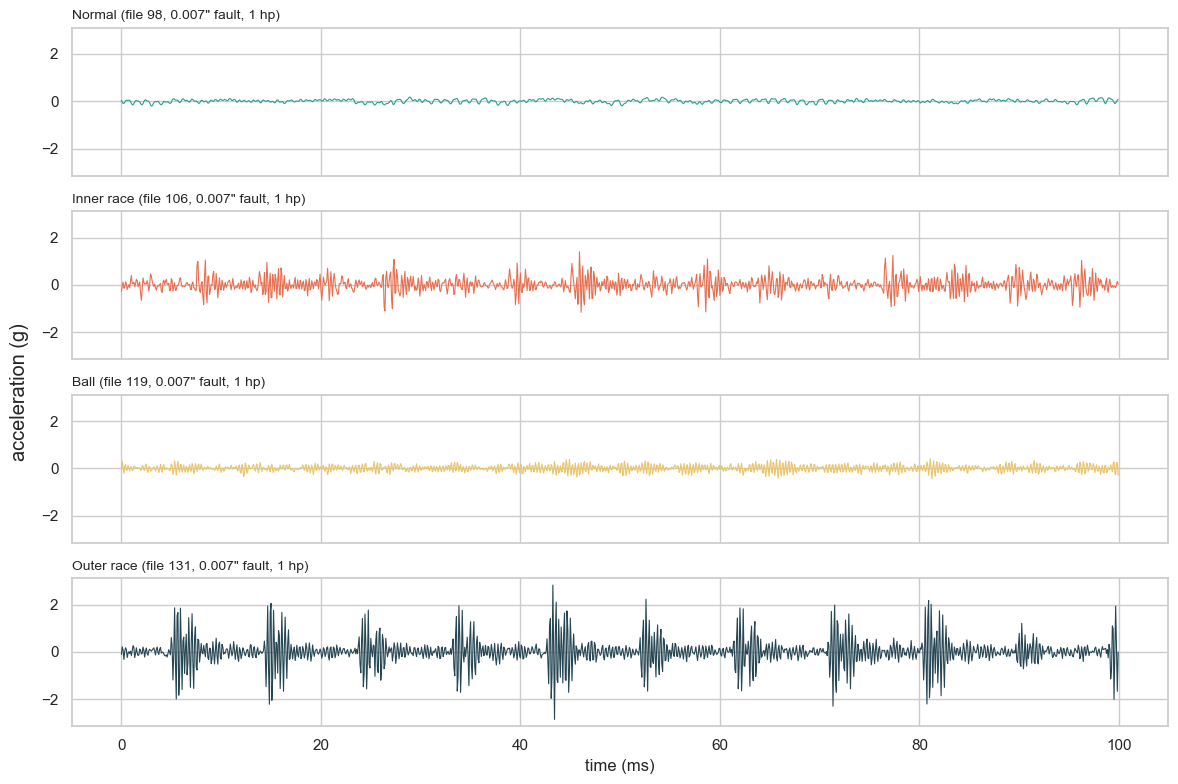

In [4]:
show = {"Normal": 98, "Inner race": 106, "Ball": 119, "Outer race": 131}  # 1 hp, smallest fault
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True, sharey=True)
for ax, (lab, fid) in zip(axes, show.items()):
    x = recs[fid][0][:int(0.1 * FS)]
    ax.plot(np.arange(len(x)) / FS * 1000, x, color=COLORS[lab], lw=0.8); ax.set_title(f"{lab} (file {fid}, 0.007\" fault, 1 hp)", loc="left", fontsize=10)
axes[-1].set_xlabel("time (ms)"); fig.supylabel("acceleration (g)"); plt.tight_layout(); plt.savefig(FIG / "waveforms.png", dpi=120); plt.show()

The inner- and outer-race faults show sharp, regularly spaced impacts even at the smallest fault size.
The ball fault is hard to see by eye: the ball spins, so the defect only hits a race part of the time.

### 3.2 Envelope spectrum: the defect frequencies
Band-pass 2-5 kHz, take the Hilbert envelope, then its spectrum. Dashed lines = theoretical defect frequencies for the SKF 6205 bearing at the measured shaft speed.

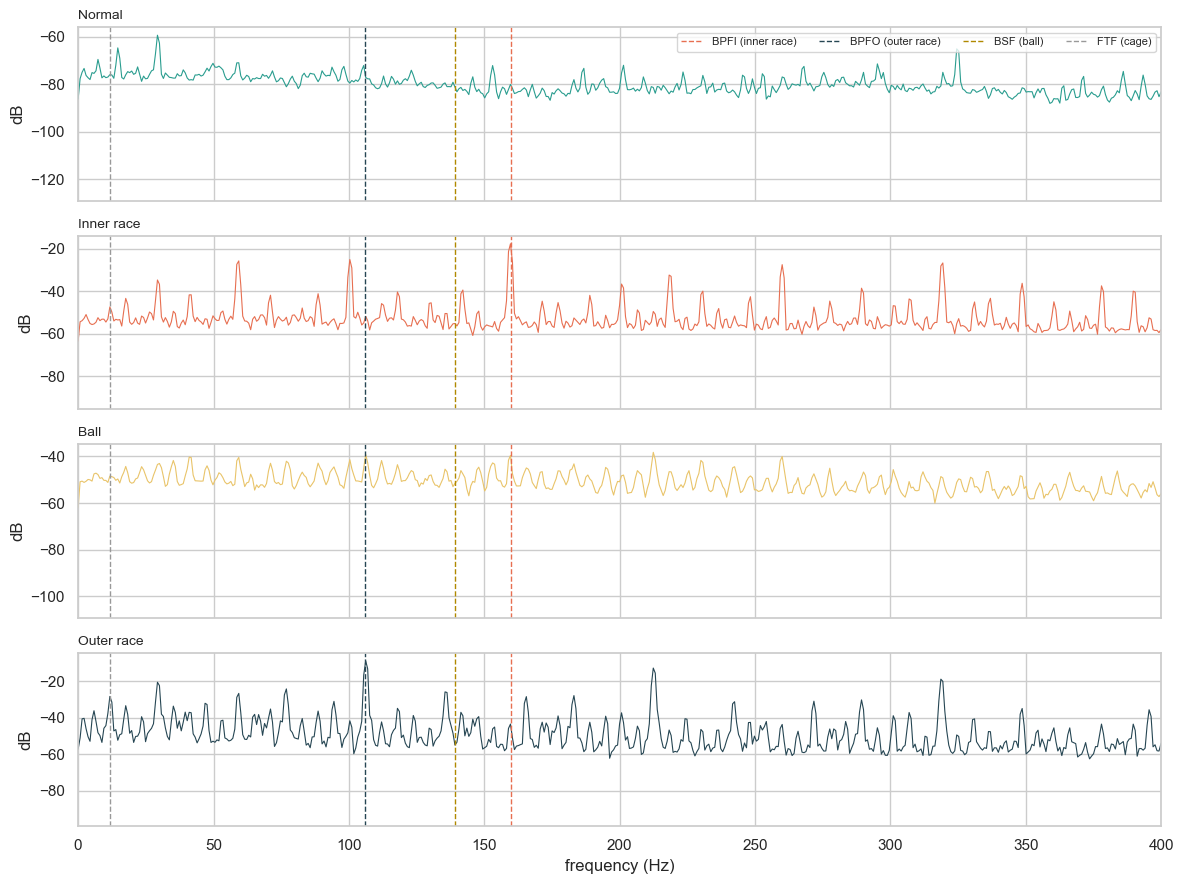

In [5]:
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
from scipy import signal as sps
for ax, (lab, fid) in zip(axes, show.items()):
    x, rpm = recs[fid]
    xf = sps.sosfiltfilt(sps.butter(4, (2000, 5000), btype="band", fs=FS, output="sos"), x)
    f, p = S.envelope_spectrum(xf, FS, n=16384)
    ax.plot(f, 10 * np.log10(p + 1e-20), color=COLORS[lab], lw=0.8)
    for (name, o), c in zip(C.DEFECT_ORDERS.items(), ["#e76f51", "#264653", "#b08900", "#999"]):
        ax.axvline(o * rpm / 60, ls="--", color=c, lw=1, label=name if lab == "Normal" else None)
    ax.set_xlim(0, 400); ax.set_title(lab, loc="left", fontsize=10); ax.set_ylabel("dB")
axes[0].legend(ncol=4, fontsize=8, loc="upper right"); axes[-1].set_xlabel("frequency (Hz)")
plt.tight_layout(); plt.savefig(FIG / "envelope_spectra.png", dpi=120); plt.show()

Inner race peaks at BPFI (~160 Hz), outer race at BPFO (~107 Hz). The physics matches the labels, so envelope features are added to the model (section 4).

### 3.3 Condition indicators by class and severity

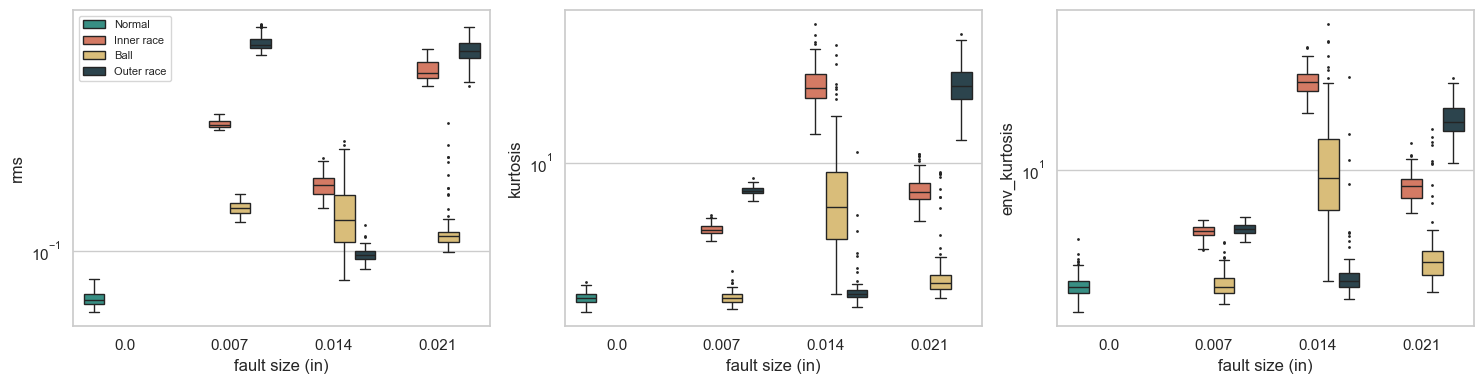

rms  kurtosis  crest
fault      size_in                       
Ball       0.007    0.14      2.89   3.44
           0.014    0.13      6.66   6.13
           0.021    0.11      3.30   3.85
Inner race 0.007    0.30      5.41   4.79
           0.014    0.18     19.88   8.74
           0.021    0.46      7.66   5.78
Normal     0.000    0.07      2.88   3.36
Outer race 0.007    0.59      7.71   4.93
           0.014    0.10      3.00   3.61
           0.021    0.56     20.16   8.51

In [6]:
rows, feats = [], []
for r in catalog.itertuples():
    w = S.windows(recs[r.file_id][0], 2048, max_windows=40)
    f = S.extract_features(w); feats.append(f); rows += [dict(fault=r.fault, size_in=r.size_in, load_hp=r.load_hp)] * len(f)
eda = pd.concat([pd.DataFrame(rows), pd.DataFrame(np.vstack(feats), columns=S.feature_names())], axis=1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["rms", "kurtosis", "env_kurtosis"]):
    sns.boxplot(data=eda, x="size_in", y=col, hue="fault", palette=COLORS, ax=ax, fliersize=1)
    ax.set_yscale("log"); ax.set_xlabel("fault size (in)"); ax.legend().remove()
axes[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG / "indicators.png", dpi=120); plt.show()
eda.groupby(["fault", "size_in"])[["rms", "kurtosis", "crest"]].median().round(2)

* **Kurtosis** (healthy ≈ 3) jumps for inner- and outer-race faults: the impacts make the distribution heavy-tailed.
* **RMS does not grow with fault size**: 0.014" faults are not louder than 0.007". A simple "vibration too high" alarm
  (the ISO 10816 approach) would miss early faults. That is the case for a learned model.
* Severity is not monotonic in CWRU (known issue: the 0.014" outer-race and ball recordings behave differently).

## 4. Features and validation design
Each recording is cut into 0.5 s windows (6000 samples, 50% overlap). Per window:
* 10 time-domain indicators (RMS, peak, kurtosis, crest factor, impulse factor ...),
* spectral shape: centroid, spectral kurtosis, 16 relative band energies of the spectrum and of the envelope spectrum,
* physics: envelope-spectrum SNR at BPFI / BPFO / BSF (needs shaft speed), absolute and relative to the strongest.

**Leakage trap.** Windows from the same recording are near-copies. A random window split puts copies in train and
test and reports ~100% for any model. Every split below is by **recording**:
* **Leave-one-load-out (LOLO):** train on 3 motor loads, test on the 4th. Answers: does it work at a load it never saw?
* **Leave-one-size-out (LOSO):** train on two fault sizes, test on the third (plus unseen healthy data). Answers: does it
  recognise a fault *size* it never saw? This is the hard, honest test.

In [7]:
rows, X = [], []
for r in catalog.itertuples():
    x, rpm = recs[r.file_id]
    w = S.windows(x, S.CLASSIFIER_WINDOW, step=S.CLASSIFIER_WINDOW // 2)
    if r.fault == "Normal":
        w = w[:40]  # cap healthy windows so each class has a similar share
    X.append(S.classifier_features(w, FS, rpm)); rows += [dict(file_id=r.file_id, fault=r.fault, size_in=r.size_in, load_hp=r.load_hp)] * len(w)
X = np.vstack(X); meta = pd.DataFrame(rows); names = S.classifier_feature_names()
y = meta.fault.map({c: i for i, c in enumerate(C.CLASSES)}).to_numpy()
print(X.shape); meta.fault.value_counts()

(1564, 51)


fault
Inner race    468
Ball          468
Outer race    468
Normal        160
Name: count, dtype: int64

In [8]:
TIME_COLS = [names.index(n) for n in S.TIME_FEATURES]
GEN_COLS = [i for i, n in enumerate(names) if not n.startswith(("snr_", "rel_"))]
MODELS = {
    "Baseline: LogReg, time-domain only": (lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=4000, class_weight="balanced")), TIME_COLS),
    "LogReg, generic features":           (lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=4000, class_weight="balanced", C=0.3)), GEN_COLS),
    "LogReg, generic + physics":          (lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=4000, class_weight="balanced", C=0.3)), list(range(len(names)))),
    "Random forest, generic + physics":   (lambda: RandomForestClassifier(400, class_weight="balanced", n_jobs=-1, random_state=0), list(range(len(names)))),
    "XGBoost, generic + physics":         (lambda: XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, n_jobs=-1, random_state=0), list(range(len(names)))),
}

def splits():
    for L in range(4):
        te = (meta.load_hp == L).to_numpy(); yield "LOLO", f"load {L}", ~te, te
    for s in (0.007, 0.014, 0.021):
        te = ((meta.size_in == s) | ((meta.fault == "Normal") & (meta.load_hp == 3))).to_numpy(); yield "LOSO", f'size {s}"', ~te, te

res = []
for name, (mk, cols) in MODELS.items():
    Xm = X[:, cols]
    rtr, rte = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=0)
    res.append(dict(model=name, scheme="Random window split (leaky)", fold="-", acc=accuracy_score(y[rte], mk().fit(Xm[rtr], y[rtr]).predict(Xm[rte]))))
    for scheme, fold, tr, te in splits():
        p = mk().fit(Xm[tr], y[tr]).predict(Xm[te])
        res.append(dict(model=name, scheme=scheme, fold=fold, acc=accuracy_score(y[te], p), f1=f1_score(y[te], p, average="macro")))
res = pd.DataFrame(res)
summary = res.groupby(["model", "scheme"]).acc.mean().unstack()[["Random window split (leaky)", "LOLO", "LOSO"]].round(3)
summary = summary.loc[list(MODELS)]; summary

scheme,Random window split (leaky),LOLO,LOSO
model,,,
"Baseline: LogReg, time-domain only",0.839,0.825,0.587
"LogReg, generic features",0.997,0.999,0.537
"LogReg, generic + physics",1.000,0.999,0.684
"Random forest, generic + physics",1.000,0.979,0.638
"XGBoost, generic + physics",1.000,0.947,0.699


In [9]:
res.pivot_table(index="model", columns="fold", values="acc").loc[list(MODELS)].drop(columns="-").round(2)

fold,load 0,load 1,load 2,load 3,"size 0.007""","size 0.014""","size 0.021"""
model,,,,,,,
"Baseline: LogReg, time-domain only",0.80,0.89,0.88,0.73,0.50,0.37,0.90
"LogReg, generic features",1.00,1.00,1.00,1.00,0.84,0.38,0.39
"LogReg, generic + physics",1.00,1.00,1.00,1.00,1.00,0.45,0.60
"Random forest, generic + physics",0.92,1.00,1.00,1.00,0.97,0.39,0.56
"XGBoost, generic + physics",0.80,1.00,1.00,0.99,0.73,0.48,0.88


## 5. Results
* **Across loads (LOLO)** the improved models are near-perfect: a model trained at three loads recognises fault types at the
  fourth. The time-domain baseline is clearly worse.
* **Across fault sizes (LOSO)** every model drops. Holding out 0.007" works (the other sizes bracket it); holding out 0.014"
  fails for every model (<50%), because the 0.014" inner- and outer-race recordings look unlike the other two sizes
  (see the kurtosis table in 3.3). Physics features lift LogReg from 0.54 to 0.68 mean LOSO accuracy. Interestingly the
  simple time-domain baseline generalises best to the held-out 0.021" size: more features also means more ways to overfit
  one test rig.
* **The leaky random split** gives ~100% for everything and would hide all of this.

So the diagnosis model should be trusted for *which part* of a bearing is failing when the fault resembles the training
data, not as a guarantee for any new machine. Early warning should not depend on it: that is the baseline detector below.

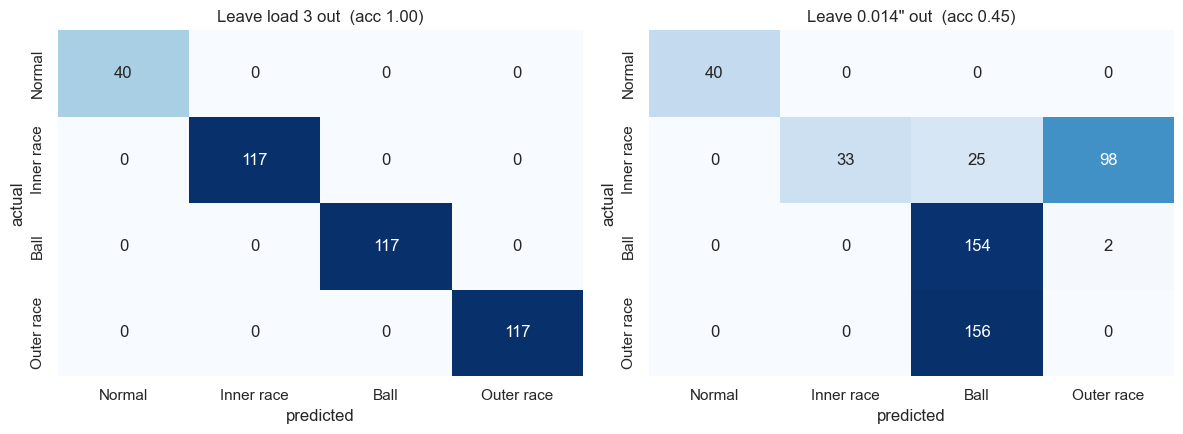

In [10]:
best = "LogReg, generic + physics"
mk, cols = MODELS[best]
te = ((meta.size_in == 0.014) | ((meta.fault == "Normal") & (meta.load_hp == 3))).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (title, tr_mask, te_mask) in zip(axes, [("Leave load 3 out", (meta.load_hp != 3).to_numpy(), (meta.load_hp == 3).to_numpy()), ('Leave 0.014" out', ~te, te)]):
    p = mk().fit(X[tr_mask][:, cols], y[tr_mask]).predict(X[te_mask][:, cols])
    sns.heatmap(confusion_matrix(y[te_mask], p, labels=range(4)), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=C.CLASSES, yticklabels=C.CLASSES, ax=ax)
    ax.set_title(f"{title}  (acc {accuracy_score(y[te_mask], p):.2f})"); ax.set_xlabel("predicted"); ax.set_ylabel("actual")
plt.tight_layout(); plt.savefig(FIG / "confusion.png", dpi=120); plt.show()

## 6. Early warning: health index against the motor's own baseline
A mill has no labelled fault data for its own motors, but it can record the motor when it is known to be healthy (after
an overhaul). The baseline detector learns that recording and flags anything that drifts away from it.

* Features: scale-free indicators only (kurtosis, crest, shape, spectral centroid, band-energy shares), so the phone's gain
  and exact position do not matter.
* Model: Mahalanobis distance to the healthy feature cloud (Ledoit-Wolf covariance). Threshold = 99th percentile of
  *held-out* healthy windows + 10%. Health index = distance / threshold, so **HI > 1 = alarm**.
* Fit on the first half of each healthy recording; test on the second half (false alarms) and on every fault recording.

In [11]:
brow, bX = [], []
for r in catalog.itertuples():
    w = S.windows(recs[r.file_id][0], 2048)
    bX.append(S.extract_features(w)); brow += [dict(file_id=r.file_id, fault=r.fault, size_in=r.size_in, load_hp=r.load_hp, idx=i, n=len(w)) for i in range(len(w))]
bmeta = pd.DataFrame(brow); bF = A.select(np.vstack(bX), S.feature_names())
healthy = (bmeta.fault == "Normal").to_numpy(); first_half = (bmeta.idx < bmeta.n // 2).to_numpy()

def evaluate(train_loads):
    fit = healthy & first_half & bmeta.load_hp.isin(train_loads).to_numpy()
    det = A.BaselineDetector().fit(bF[fit]); hi = det.health_index(bF)
    held = healthy & ~first_half
    out = {"baseline loads": str(train_loads)}
    out.update({f"false alarm, load {L}": (hi[held & (bmeta.load_hp == L).to_numpy()] > 1).mean() for L in range(4)})
    for s in (0.007, 0.014, 0.021):
        out[f'detected {s}"'] = (hi[(bmeta.size_in == s).to_numpy()] > 1).mean()
    return out, det, hi

ew = pd.DataFrame([evaluate(t)[0] for t in ([0, 1, 2, 3], [0, 1, 2], [1, 2, 3])]).set_index("baseline loads")
ew.round(3)

,"false alarm, load 0","false alarm, load 1","false alarm, load 2","false alarm, load 3","detected 0.007""","detected 0.014""","detected 0.021"""
baseline loads,,,,,,,
"[0, 1, 2, 3]",0.0,0.017,0.0,0.000,1.0,1.0,1.0
"[0, 1, 2]",0.0,0.000,0.0,0.017,1.0,1.0,1.0
"[1, 2, 3]",1.0,0.008,0.0,0.000,1.0,1.0,1.0


* With a baseline covering the motor's operating range, **every fault window of every size is flagged, including the
  smallest 0.007" faults**, with false alarms of 0-2% per window.
* A baseline recorded at loads 0-2 still works at the unseen load 3 (~2% window false alarms).
  A baseline at loads 1-3 flags the 0 hp healthy recording (file 97) as abnormal: **record the baseline across the loads
  the motor normally runs at**. Alarms should also be raised on a run of windows, not a single window (next cell).

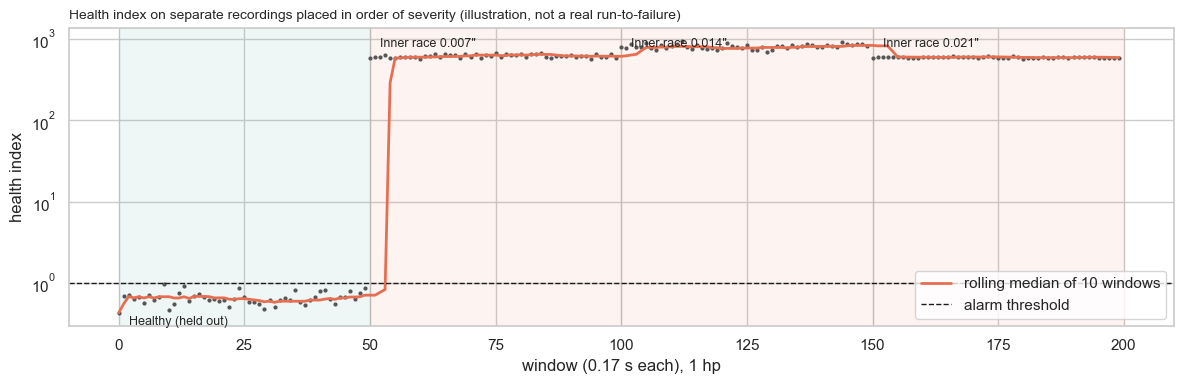

In [12]:
_, det, hi = evaluate([0, 1, 2, 3])
bmeta["hi"] = hi
seq = [("Normal", 0.0), ("Inner race", 0.007), ("Inner race", 0.014), ("Inner race", 0.021)]
parts = [bmeta[(bmeta.fault == f) & (bmeta.size_in == s) & (bmeta.load_hp == 1) & ((bmeta.fault != "Normal") | (bmeta.idx >= bmeta.n // 2))].head(50) for f, s in seq]
tl = pd.concat(parts, ignore_index=True)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(tl.index, tl.hi, ".", color="#555", ms=4); ax.plot(tl.index, tl.hi.rolling(10, min_periods=1).median(), color="#e76f51", lw=2, label="rolling median of 10 windows")
ax.axhline(1, color="k", ls="--", lw=1, label="alarm threshold")
for k, (f, s) in enumerate(seq):
    ax.axvspan(k * 50, k * 50 + 50, color=COLORS[f], alpha=0.08); ax.text(k * 50 + 2, ax.get_ylim()[1] * 0.8 if k else 0.3, f"{f} {s}\"" if s else "Healthy (held out)", fontsize=9)
ax.set_yscale("log"); ax.set_xlabel("window (0.17 s each), 1 hp"); ax.set_ylabel("health index"); ax.legend(loc="lower right")
ax.set_title("Health index on separate recordings placed in order of severity (illustration, not a real run-to-failure)", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "health_index.png", dpi=120); plt.show()

## 7. Feature importance
Which indicators drive the diagnosis? Permutation importance of the production model on the leave-load-3-out test set.

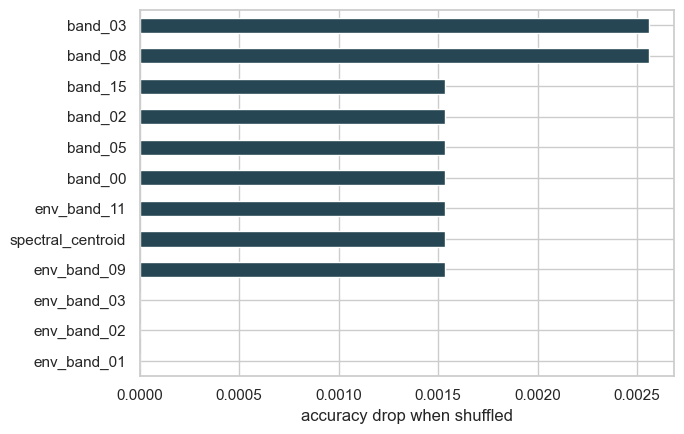

In [13]:
from sklearn.inspection import permutation_importance
tr, te = (meta.load_hp != 3).to_numpy(), (meta.load_hp == 3).to_numpy()
m = MODELS[best][0]().fit(X[tr], y[tr])
pi = permutation_importance(m, X[te], y[te], n_repeats=5, random_state=0, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=names).sort_values(ascending=False).head(12)
imp.sort_values().plot.barh(figsize=(7, 4.5), color="#264653"); plt.xlabel("accuracy drop when shuffled"); plt.tight_layout(); plt.savefig(FIG / "importance.png", dpi=120); plt.show()

## 8. Train the production models and export
* **Fault classifier:** the best model (LogReg on generic + physics features), refit on all 40 recordings.
* The baseline detector is not exported: it is fitted per motor, from that motor's own healthy recording, at request time.
* Demo clips (10 s healthy, 3 s faulty) are saved to `data/samples/` for the web app.

In [14]:
final = MODELS[best][0]().fit(X, y)
models_dir = ROOT / "models"; models_dir.mkdir(exist_ok=True)
joblib.dump(final, models_dir / "fault_classifier.joblib")
lolo = summary.loc[best, "LOLO"]; loso = summary.loc[best, "LOSO"]
meta_out = {
    "model": best, "classes": C.CLASSES, "feature_names": names, "sample_rate_hz": S.CLASSIFIER_FS,
    "window_samples": S.CLASSIFIER_WINDOW, "default_rpm": 1797, "bearing": "SKF 6205-2RS (CWRU drive end)",
    "trained_on": "CWRU 12 kHz drive-end, 40 recordings, loads 0-3 hp, fault sizes 0.007/0.014/0.021 in",
    "validation": {"leave_one_load_out_acc": round(float(lolo), 3), "leave_one_size_out_acc": round(float(loso), 3),
                   "per_fold": res[res.model == best].drop(columns="model").round(3).fillna("").to_dict("records")},
    "baseline_detector": {k: {kk: round(float(v), 3) for kk, v in row.items()} for k, row in ew.iterrows()},
}
(models_dir / "model_metadata.json").write_text(json.dumps(meta_out, indent=2))
summary.to_csv(models_dir / "model_comparison.csv")

samples = ROOT / "data" / "samples"; samples.mkdir(parents=True, exist_ok=True)
demo = {"healthy_1hp": 98, "healthy_0hp": 97, "inner_race_007_1hp": 106, "ball_007_1hp": 119, "outer_race_007_1hp": 131,
        "inner_race_021_2hp": 211, "outer_race_021_2hp": 236}
for name, fid in demo.items():
    x, rpm = recs[fid]; start = len(x) // 2 if "healthy" in name else 0
    np.savez_compressed(samples / f"{name}.npz", signal=x[start:start + (10 if "healthy" in name else 3) * FS].astype(np.float32), fs=FS, rpm=rpm,
                        source=f"CWRU file {fid}, {catalog.set_index('file_id').loc[fid, 'fault']}")
print(json.dumps({k: meta_out[k] for k in ["model", "validation"]}, indent=1)[:600])

{
 "model": "LogReg, generic + physics",
 "validation": {
  "leave_one_load_out_acc": 0.999,
  "leave_one_size_out_acc": 0.684,
  "per_fold": [
   {
    "scheme": "Random window split (leaky)",
    "fold": "-",
    "acc": 1.0,
    "f1": ""
   },
   {
    "scheme": "LOLO",
    "fold": "load 0",
    "acc": 0.997,
    "f1": 0.998
   },
   {
    "scheme": "LOLO",
    "fold": "load 1",
    "acc": 1.0,
    "f1": 1.0
   },
   {
    "scheme": "LOLO",
    "fold": "load 2",
    "acc": 1.0,
    "f1": 1.0
   },
   {
    "scheme": "LOLO",
    "fold": "load 3",
    "acc": 1.0,
    "f1": 1.0
   },
   {
    "


## 9. Own data: phone recordings of a fan
Put recordings in `data/phone/healthy/` and `data/phone/faulty/` (`.csv` accelerometer export from phyphox, or `.wav`).
See `data/phone/README.md` for how to record. This section fits the baseline detector on the healthy recordings and reports
the health index of every recording. It skips when the folders are empty.

In [15]:
phone = ROOT / "data" / "phone"
files = {lab: sorted(p for p in (phone / lab).glob("*") if p.suffix.lower() in (".csv", ".wav")) for lab in ("healthy", "faulty")}
if not files["healthy"]:
    print("No phone recordings yet in data/phone/healthy - skipping. See data/phone/README.md.")
else:
    def feats(p):
        x, fs, desc = S.load_recording(p.read_bytes(), p.name)
        return S.extract_features(S.windows(x, S.baseline_window(fs))), fs, desc
    H = [feats(p) for p in files["healthy"]]
    print("healthy:", [(p.name, round(fs), d) for p, (_, fs, d) in zip(files["healthy"], H)])
    Hf = np.vstack([h[0] for h in H]); det = A.BaselineDetector().fit(A.select(Hf, S.feature_names()))
    out = []
    for lab in ("healthy", "faulty"):
        for p in files[lab]:
            f, fs, _ = feats(p); hi = det.health_index(A.select(f, S.feature_names()))
            out.append(dict(file=p.name, label=lab, windows=len(hi), median_HI=np.median(hi), alarm_share=(hi > 1).mean()))
    display(pd.DataFrame(out).round(2))
    print("Note: healthy files were used to fit the baseline, so their scores are optimistic. Record a separate healthy file to test false alarms.")

No phone recordings yet in data/phone/healthy - skipping. See data/phone/README.md.


## 10. Conclusions
1. **Fault signatures are physical and visible:** inner- and outer-race faults produce impacts at BPFI / BPFO that show up
   clearly in the envelope spectrum even at 0.007" (0.18 mm).
2. **Overall vibration level is a weak alarm:** RMS does not rise with fault size, while kurtosis and envelope features do.
3. **Validation matters more than the model:** a random window split reports ~100% for every model. Splitting by recording
   shows near-perfect transfer across motor loads but large drops on an unseen fault size.
4. **Early warning works without fault labels:** a per-motor baseline flags every CWRU fault, including the smallest, with low
   false alarms, provided the baseline covers the motor's normal load range.

**Limitations.** CWRU faults are seeded (EDM-cut) on one test rig, not naturally grown; the diagnosis model is tied to the
SKF 6205 geometry and 12 kHz sampling. Phone accelerometers sample at 100-500 Hz, far below the 2-5 kHz band the classifier
uses, so phone data goes through the baseline detector only. Next steps: run-to-failure data (IMS / XJTU-SY) for remaining
useful life, and a cheap 10 kHz+ MEMS sensor (ADXL345/ESP32) for real mill motors.